# Figure 3 — short test

Angle and push cohorts, input learning, neural activity, AN–DN interventions and gain planes.

The saved tables and figures below come from a real short test and can be viewed directly on GitHub. To regenerate them, use the **Python (FlyControl)** kernel; see [setup and notebook index](README.md). Run cells from top to bottom. This notebook executes the same six stages as the command-line workflow, with reduced budgets and one training seed. It keeps every configured method. **These are software checks, not paper results.**

First execution downloads versioned public inputs. Neural assays and multi-stage maze prerequisites can still take substantial time; “short” refers to the training budget, not a seconds-long demonstration. Generated checkpoints, data and figures stay under `runs/`.

Choose a fresh `RUN_DIR` after code/configuration changes or for an independent restart. A completed run can be inspected with the “Inspect the smoke outputs” cell without retraining.

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'turning'
RUN_DIR = ROOT / "runs/notebooks" / CONFIG
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: turning | cuda:0 | runs/notebooks/turning


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 58.0 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 441.1 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 1172.5 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 2422.2 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 3.1 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 17.9 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,turning,"connectome, mlp, er",[4301]


Source/configuration SHA-256: `eaab77b7c7f8b5c50e7015c4c1c15e9ce272e2e432760c88fcc2e24c7a48ea9f`

,stage,completed,elapsed seconds
0,prepare,True,57.98
1,train,True,441.06
2,evaluate,True,1172.46
3,probe,True,2422.18
4,analyze,True,3.14
5,plot,True,17.93


`analysis/seed_means.csv` (first eight rows)

...

`analysis/episodes.csv` (first eight rows)

,family,seed,method,phase,angle,force,side,terminal_error,success,failure,...,speed,relative_command_roughness,late_heading_upright_fraction,last_window_error,recovery_auc,source,source_sha256,initial_state,initial_obs,condition
0,angle,4301,connectome,790000,-30.0,0.0,0.0,10.292082,0.0,0.0,...,14.689151,1.918512,0.26,13.656946,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,027b07aa68aea1f71c7827599738bd779fc6bb7af65777...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,-30°
1,angle,4301,connectome,790000,-60.0,0.0,0.0,63.814142,0.0,0.0,...,14.169642,1.943713,0.00,60.216336,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,0792b179d748f07a4558967816c2d6c675848043513e8a...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,-60°
2,angle,4301,connectome,790000,-90.0,0.0,0.0,80.779199,0.0,0.0,...,14.786846,1.923801,0.00,85.342295,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,fe78b4b321bdad7a9c8188c539c7412dce146255f416a9...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,-90°
3,angle,4301,connectome,790000,30.0,0.0,0.0,41.998797,0.0,0.0,...,14.757658,1.848235,0.00,50.090404,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,b85565678523c986c6f25cd989d4f6393dedb6c30fbbbd...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,30°
4,angle,4301,connectome,790000,60.0,0.0,0.0,75.038447,0.0,0.0,...,14.779364,1.921188,0.00,75.215706,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,e40d470f8462a60665e2a5510c17f8cdc862ad955518d7...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,60°
5,angle,4301,connectome,790000,90.0,0.0,0.0,104.806040,0.0,0.0,...,14.799442,1.957037,0.00,101.375817,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,16b31e09880208661e95b783dfcc4d7af4f6e2795716fc...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,90°
6,angle,4301,er,790000,-30.0,0.0,0.0,8.110425,0.0,0.0,...,15.018784,1.737752,0.88,5.589070,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,4d5027a7991484cb1e9ac66930d7a472c58cf771e95639...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,-30°
7,angle,4301,er,790000,-60.0,0.0,0.0,25.698550,0.0,0.0,...,14.504457,1.726719,0.00,27.932681,0.0,/data2/ysy/github/FlyControl/runs/notebooks/tu...,c443aceb8d2e3266c3c376775f62d17d058076c1976caa...,08083f79b037d5157e53d40dee637f1f86b73ef57ddf97...,2b5a6680f9d9a91b784f2165f3ccb378cc15323eb955d5...,-60°


`analysis/observed_counts.csv` (first eight rows)

,method,seed,condition,terminal_error,relative_command_roughness,command_variation,success,failure
0,connectome,4301,-30°,1,1,1,1,1
1,connectome,4301,-60°,1,1,1,1,1
2,connectome,4301,-90°,1,1,1,1,1
3,connectome,4301,30°,1,1,1,1,1
4,connectome,4301,60°,1,1,1,1,1
5,connectome,4301,90°,1,1,1,1,1
6,er,4301,-30°,1,1,1,1,1
7,er,4301,-60°,1,1,1,1,1


`figures/paper/F3_AN_DN_interventions.png`

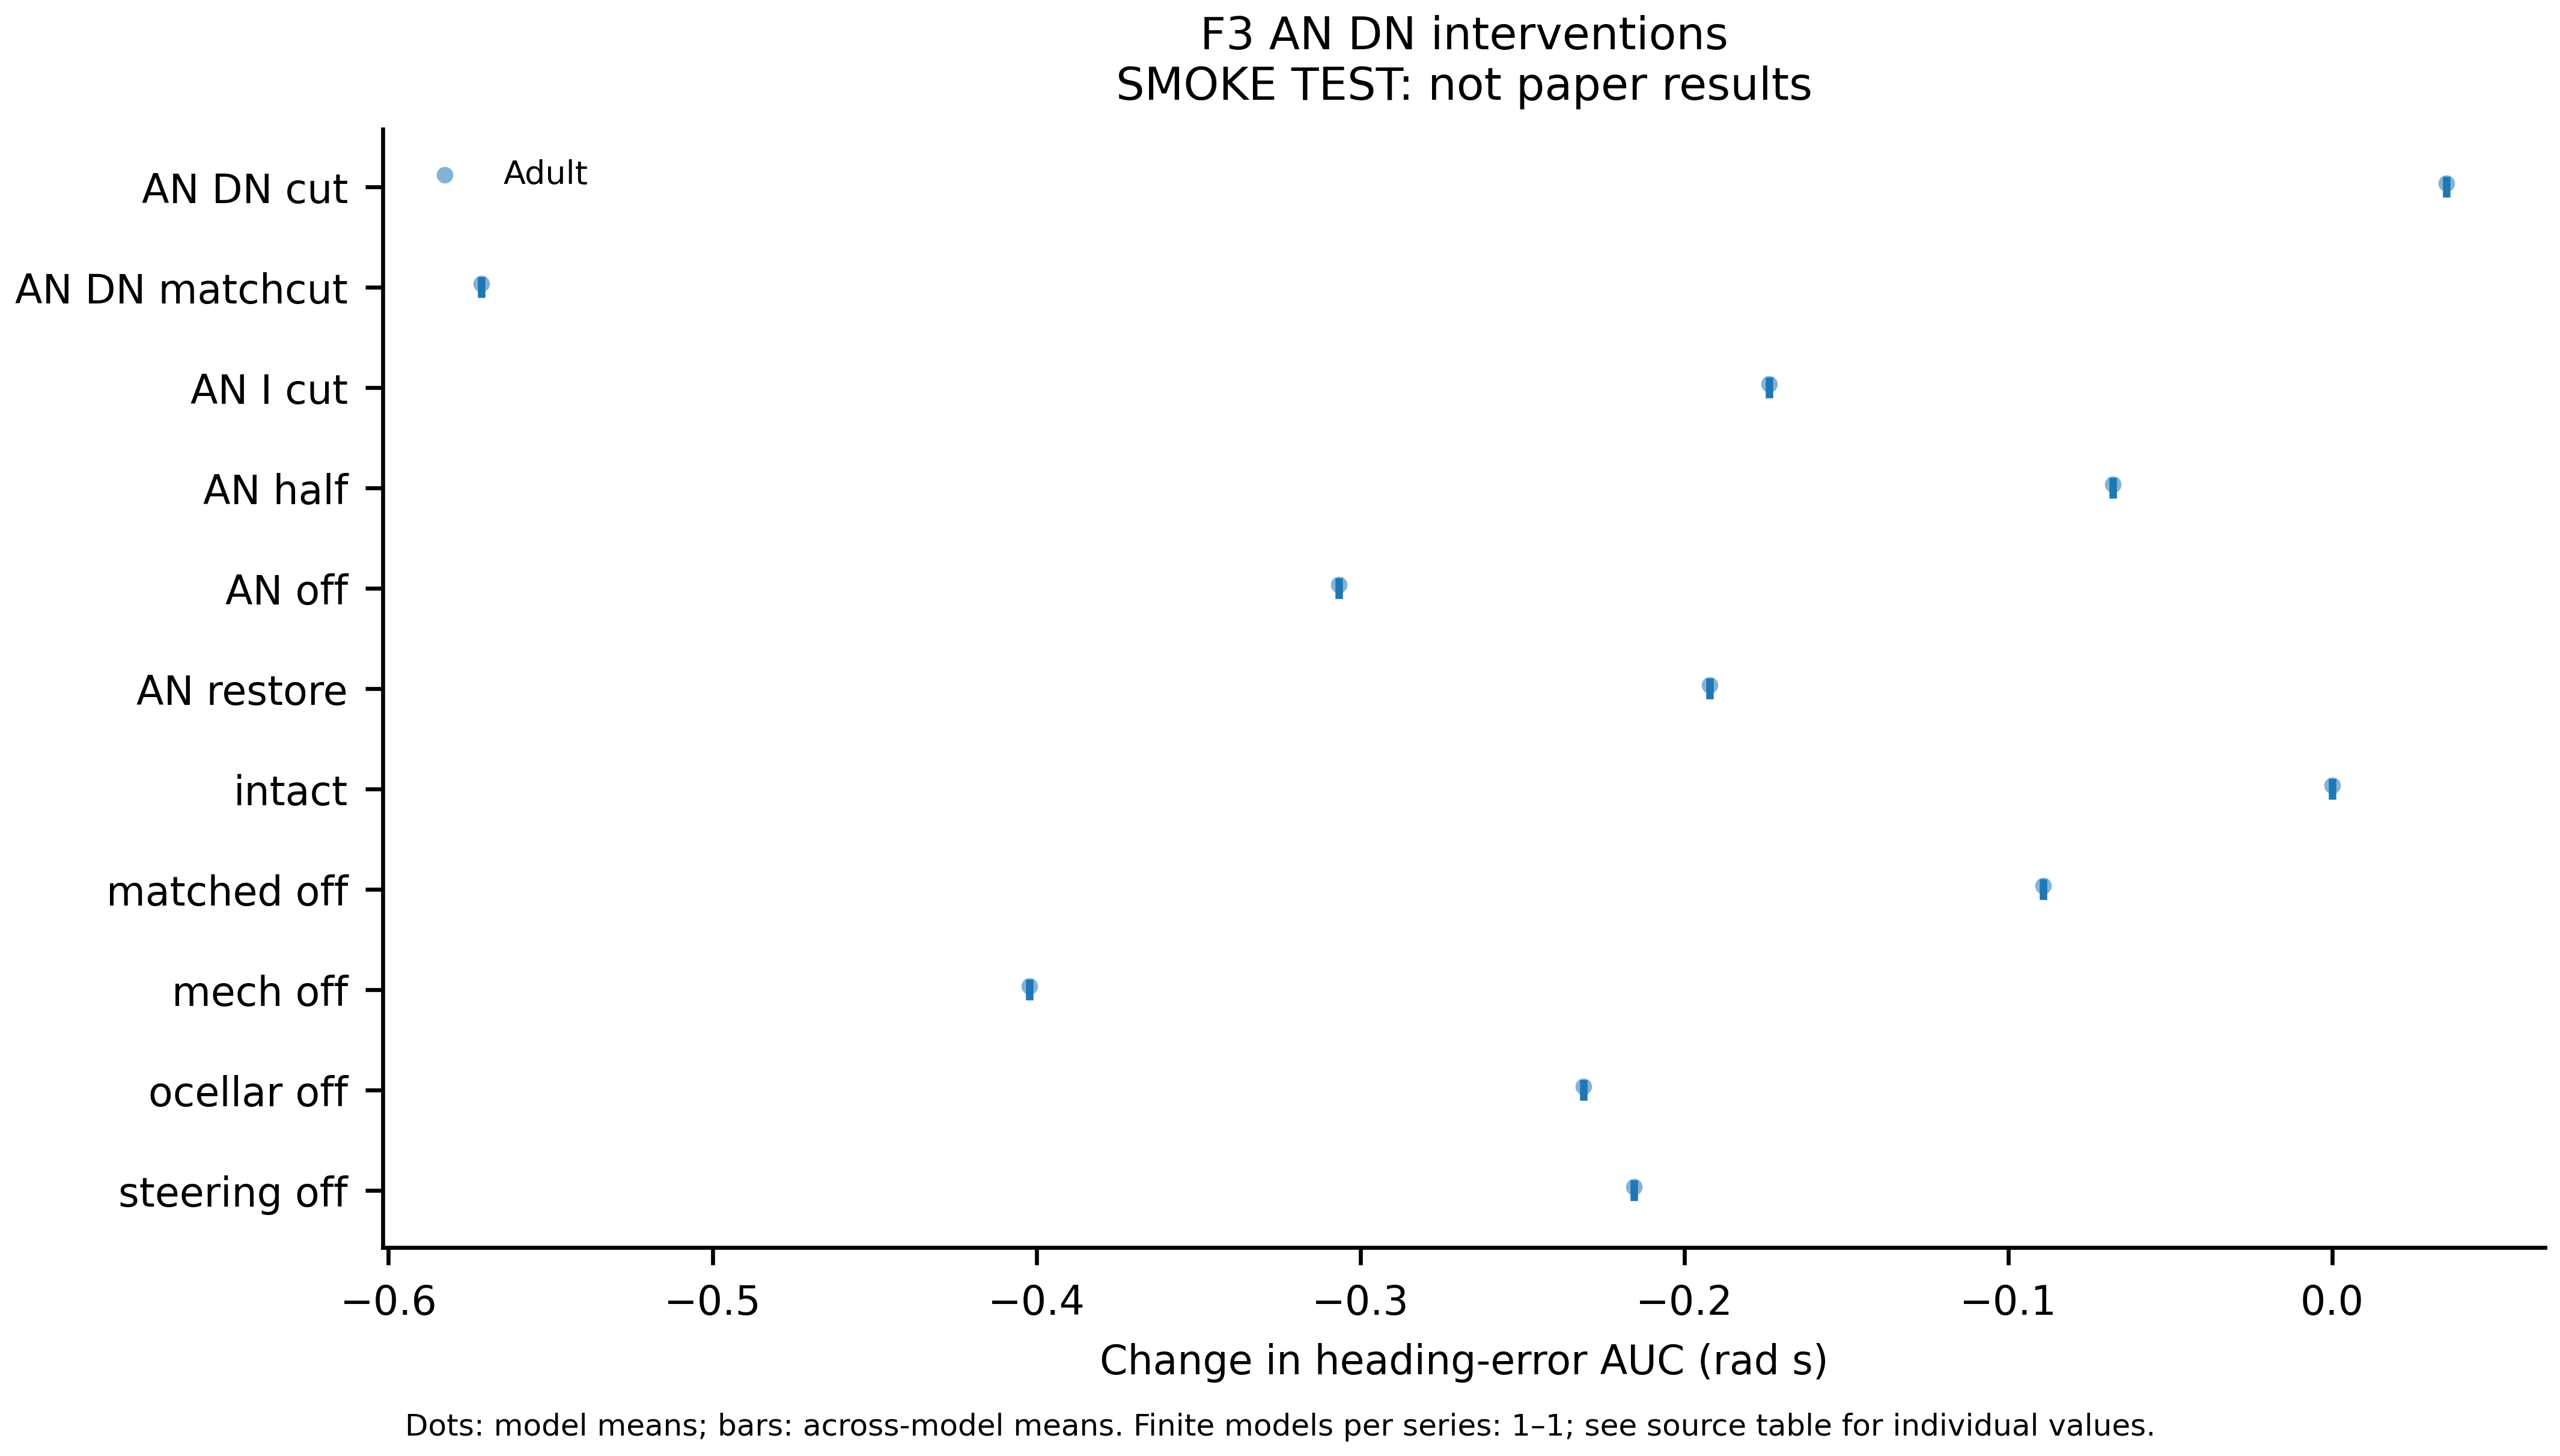

`figures/paper/F3_interface_exchange.png`

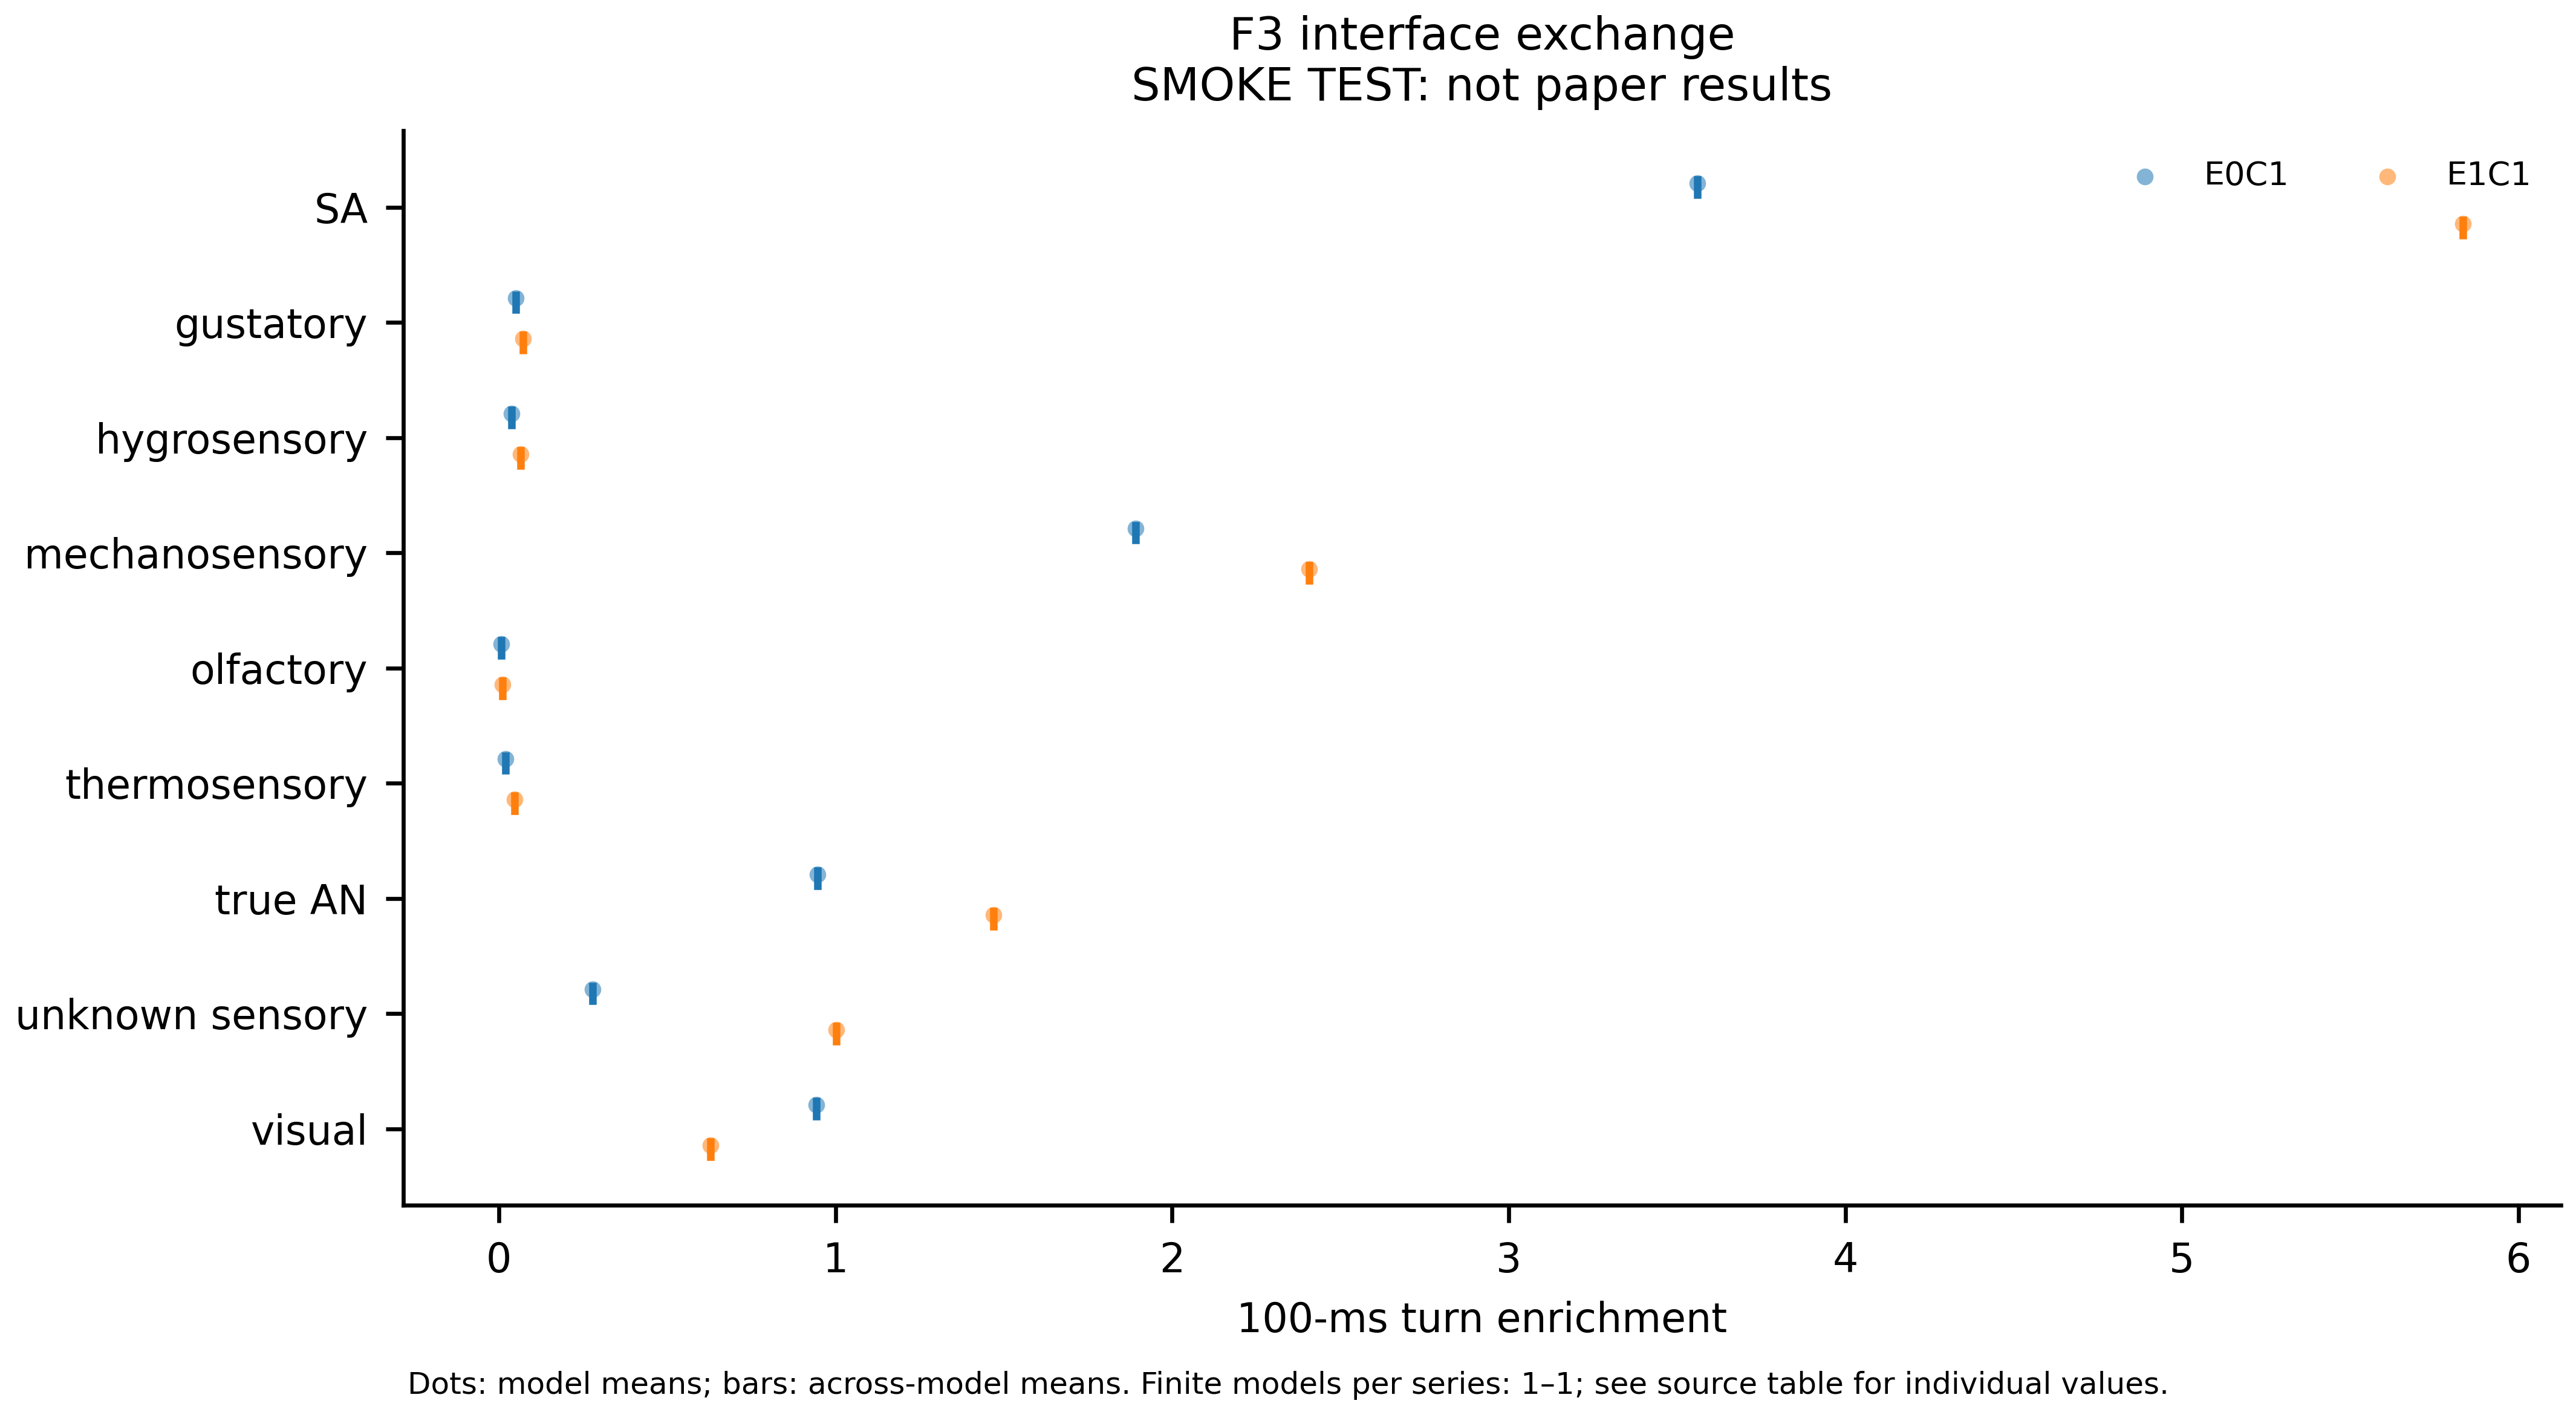

`figures/paper/F3_neural_sensitivity.png`

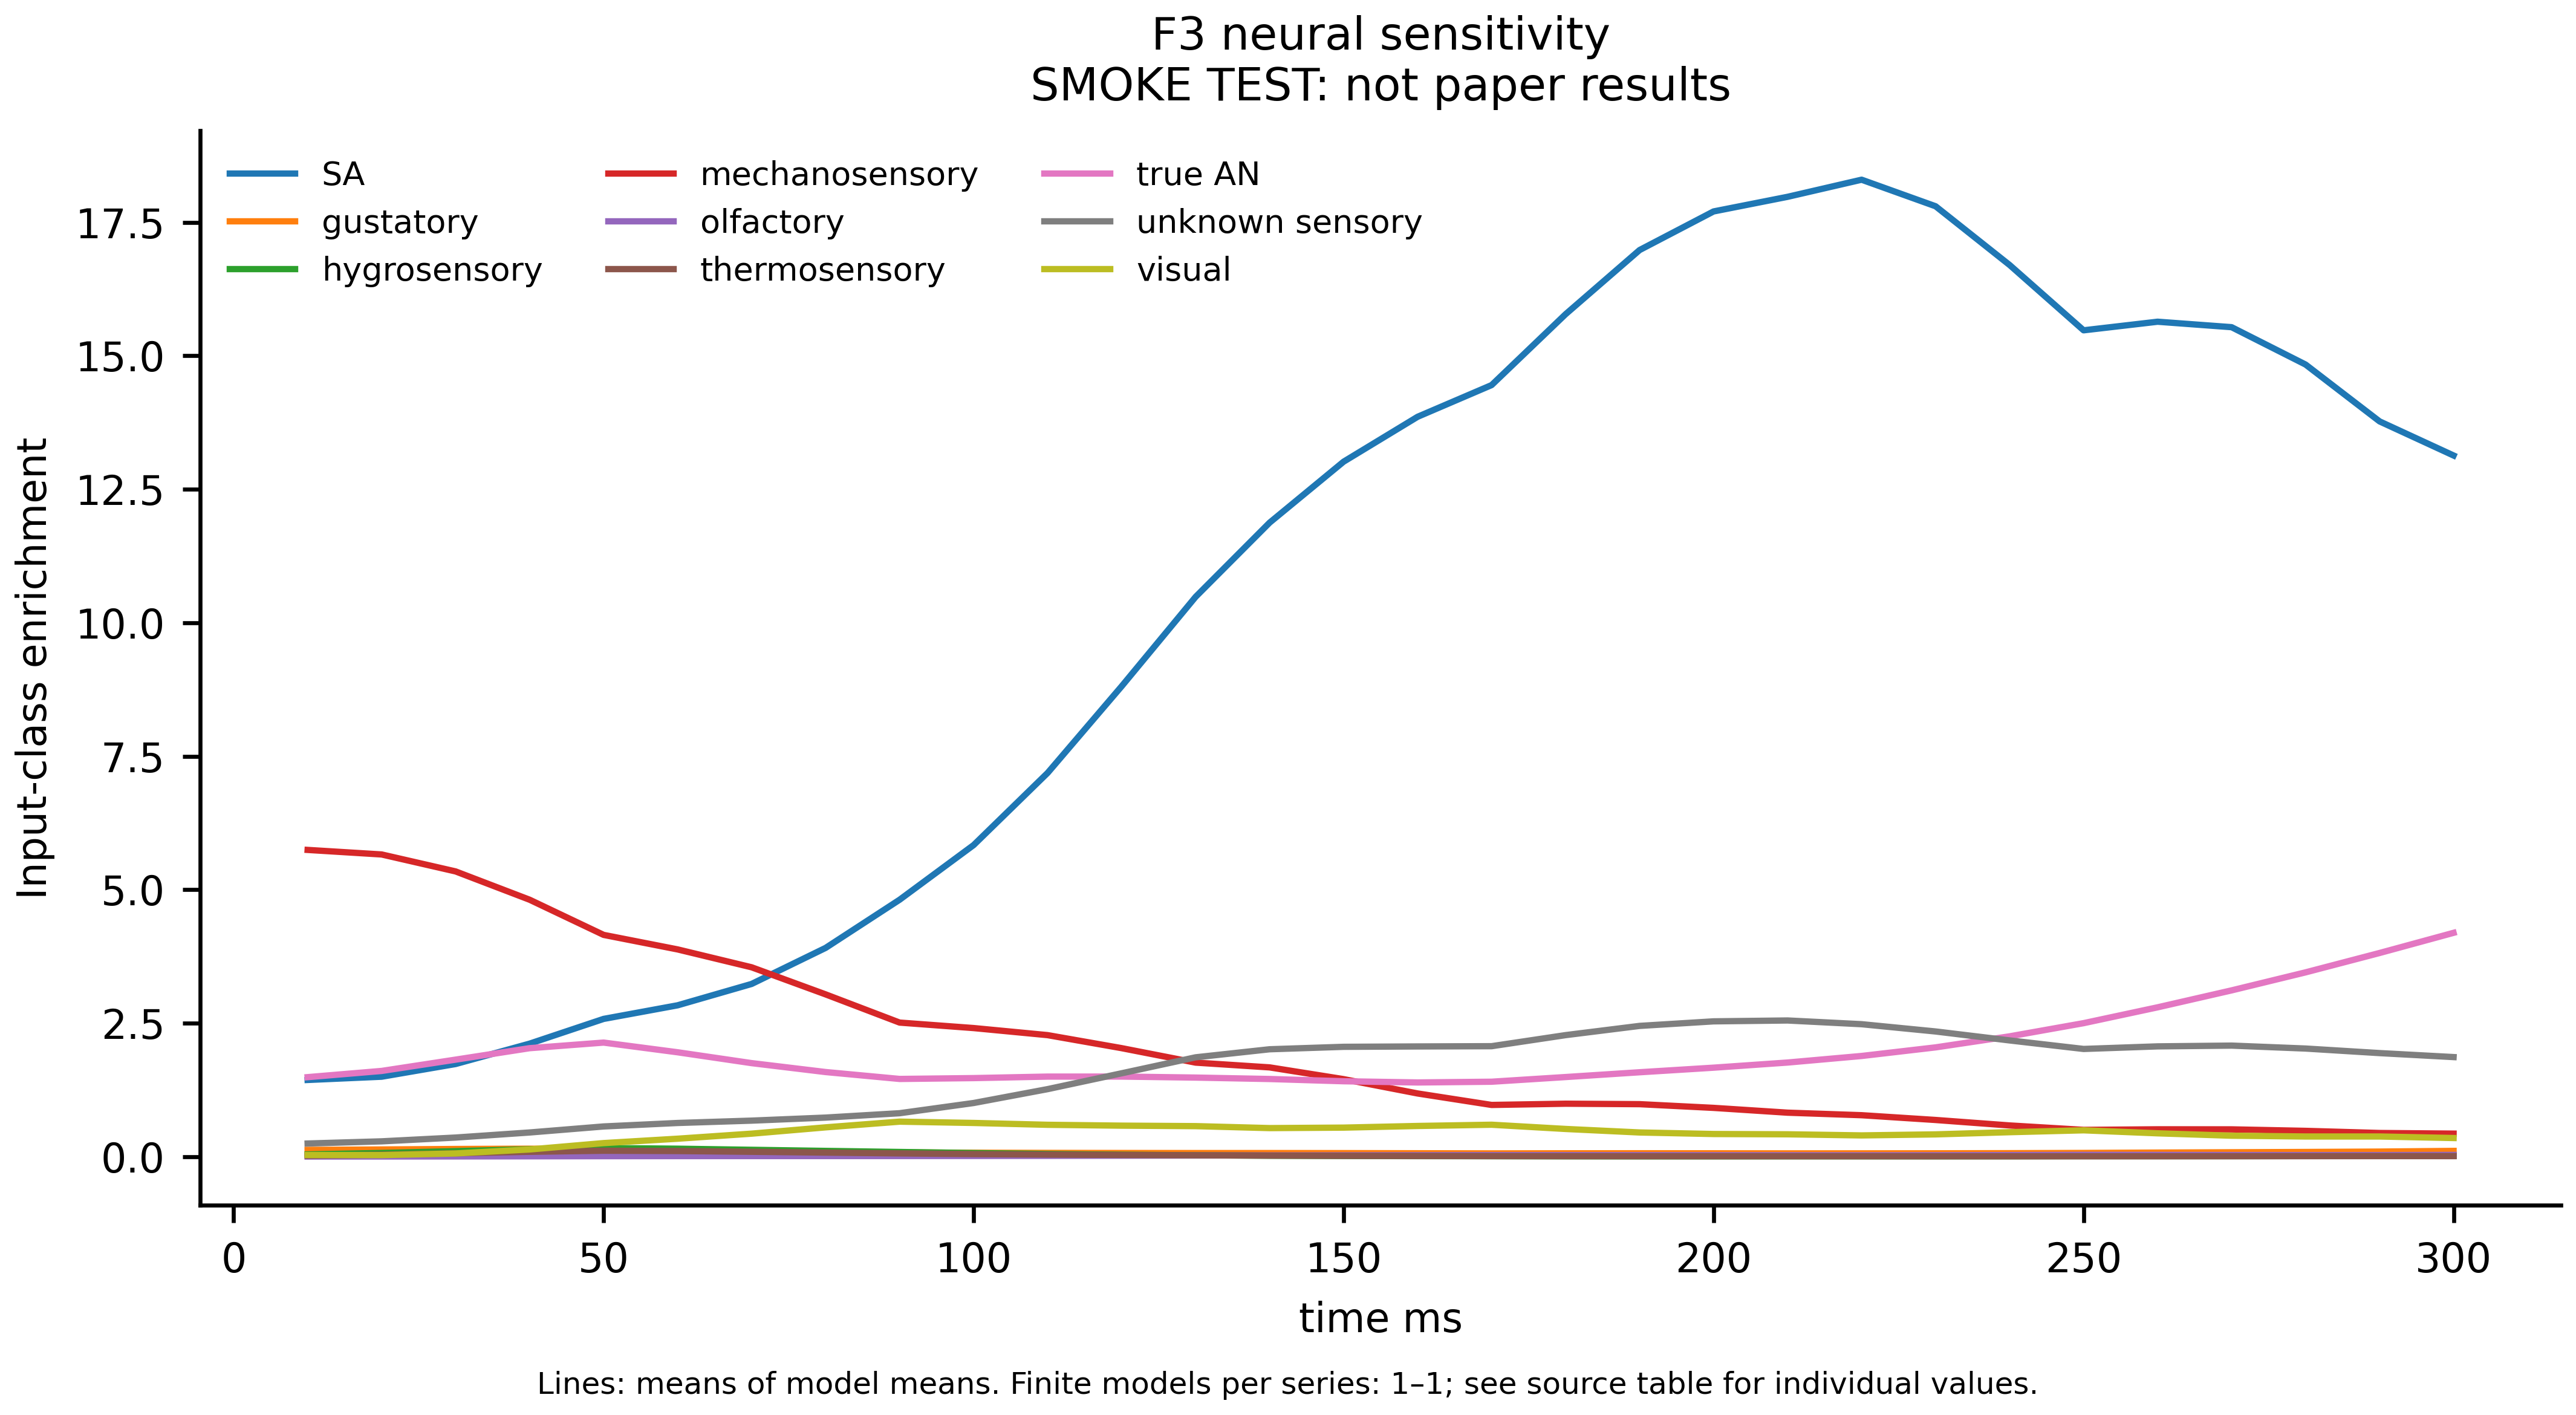

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/03_turning.py --run-dir runs/turning --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config turning --run-dir runs/turning --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.
